# 01 — FMCW Range-Doppler Dataset Generator

Application profile: **front-facing 77 GHz automotive FMCW radar** for AEB/ACC-style target detection.

This notebook is only for generating RD maps and labels. CFAR and DL detection should be done in separate notebooks using the saved samples.


## Imports

In [1]:
# ============================================================
# 1. Imports
# ============================================================

import json
from pathlib import Path
from dataclasses import dataclass, asdict
import csv 

import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi
from scipy import signal


## Radar Parameters

In [2]:
# ============================================================
# 2. Frozen radar profile: 77 GHz automotive FMCW
# ============================================================

@dataclass(frozen=True)
class RadarConfig:
    fc: float = 77e9
    B: float = 300e6
    Tc: float = 32e-6
    N: int = 512
    M: int = 128

config = RadarConfig()

lambda_m = c / config.fc
slope = config.B / config.Tc
fs = config.N / config.Tc
Ts = 1 / fs

range_res = c / (2 * config.B)
range_max = c * fs / (4 * slope)
vel_res = lambda_m / (2 * config.M * config.Tc)
vel_max = lambda_m / (4 * config.Tc)

print("Frozen Automotive FMCW Radar Profile")
print("=====================================")
print(f"fc        : {config.fc/1e9:.1f} GHz")
print(f"lambda    : {lambda_m*1e3:.3f} mm")
print(f"B         : {config.B/1e6:.1f} MHz")
print(f"Tc        : {config.Tc*1e6:.1f} us")
print(f"N         : {config.N}")
print(f"M         : {config.M}")
print(f"fs        : {fs/1e6:.2f} MHz")
print(f"Ts        : {Ts*1e9:.2f} ns")
print(f"slope     : {slope/1e12:.3f} THz/s")
print(f"range_res : {range_res:.3f} m")
print(f"range_max : {range_max:.1f} m")
print(f"vel_res   : {vel_res:.3f} m/s")
print(f"vel_max   : ±{vel_max:.2f} m/s")


Frozen Automotive FMCW Radar Profile
fc        : 77.0 GHz
lambda    : 3.893 mm
B         : 300.0 MHz
Tc        : 32.0 us
N         : 512
M         : 128
fs        : 16.00 MHz
Ts        : 62.50 ns
slope     : 9.375 THz/s
range_res : 0.500 m
range_max : 127.9 m
vel_res   : 0.475 m/s
vel_max   : ±30.42 m/s


## Targets - SNR

In [3]:
# ============================================================
# 3. Flexible scene / dataset parameters
# ============================================================

# Tuple format: (range_m, velocity_mps, relative_amplitude_db)
targets = [
    (22.0, -6.0, 12.0),
    (48.0,  20,  1.0),
    (70.0,  7.0, -6.0),
]

snr_db = 0
seed = 42

clutter_enabled = False
clutter_strength_db = -18
clutter_width_bins = 3

multipath_enabled = False
multipath_delay_m = 2.0
multipath_attenuation_db = -12

r_plot_max = 100.0
v_plot_max = 30.0
cmap = "inferno"
vmin_db = -60
vmax_db = 0

save_single_frame = True
output_dir = Path("data/generated/sample_000001")

# Optional dataset generation
make_dataset = False
num_frames = 10
snr_choices = [-10, -5, 0, 5, 10, 15, 20]
num_targets_min = 0
num_targets_max = 5
dataset_dir = Path("data/generated/dataset_v1")


## FMCW Simulation + RD functions

In [4]:
# ============================================================
# 4. FMCW simulation and RD processing functions
# ============================================================

def db_to_amp(x_db):
    return 10 ** (np.asarray(x_db) / 20)


def make_axes(cfg):
    t_fast = np.arange(cfg.N) / fs
    t_abs = np.arange(cfg.M)[:, None] * cfg.Tc + t_fast[None, :]

    freq_axis = np.fft.fftfreq(cfg.N, d=1/fs)[:cfg.N // 2]
    range_axis = freq_axis * c / (2 * slope)

    doppler_axis = np.fft.fftshift(np.fft.fftfreq(cfg.M, d=cfg.Tc))
    velocity_axis = doppler_axis * lambda_m / 2

    return t_fast, t_abs, range_axis, velocity_axis


def validate_targets(target_list, cfg):
    for i, (r, v, amp_db) in enumerate(target_list, start=1):
        fb = 2 * r * slope / c
        if fb >= fs / 2:
            raise ValueError(f"Target {i}: range {r} m exceeds Nyquist beat limit.")
        if abs(v) >= vel_max:
            raise ValueError(f"Target {i}: velocity {v:+.2f} m/s exceeds ±{vel_max:.2f} m/s.")


def generate_tx(cfg):
    t_fast, t_abs, _, _ = make_axes(cfg)
    t_chirp = t_fast[None, :]
    return np.exp(1j * 2*pi * (cfg.fc * t_abs + 0.5 * slope * t_chirp**2))


def generate_dechirped_cpi(target_list, cfg):
    validate_targets(target_list, cfg)

    t_fast, t_abs, _, _ = make_axes(cfg)
    t_chirp = t_fast[None, :]

    tx = generate_tx(cfg)
    rx = np.zeros((cfg.M, cfg.N), dtype=np.complex128)

    for r0, v, amp_db in target_list:
        amp = db_to_amp(amp_db)
        r_t = r0 + v * t_abs
        tau = 2 * r_t / c

        rx += amp * np.exp(
            1j * 2*pi * (
                cfg.fc * (t_abs - tau) +
                0.5 * slope * (t_chirp - tau)**2
            )
        )

        if multipath_enabled:
            r_mp = r0 + multipath_delay_m + v * t_abs
            tau_mp = 2 * r_mp / c
            rx += amp * db_to_amp(multipath_attenuation_db) * np.exp(
                1j * 2*pi * (
                    cfg.fc * (t_abs - tau_mp) +
                    0.5 * slope * (t_chirp - tau_mp)**2
                )
            )

    return tx * np.conj(rx)


def add_awgn(x, snr_db, seed=None):
    rng = np.random.default_rng(seed)
    signal_power = np.mean(np.abs(x)**2)
    noise_power = signal_power / (10 ** (snr_db / 10))
    noise = np.sqrt(noise_power / 2) * (rng.standard_normal(x.shape) + 1j*rng.standard_normal(x.shape))
    return x + noise


def add_near_zero_doppler_clutter(cpi, strength_db=-18, width_bins=3, seed=None):
    rng = np.random.default_rng(seed)
    amp = db_to_amp(strength_db)
    clutter = amp * (rng.standard_normal(cpi.shape) + 1j*rng.standard_normal(cpi.shape)) / np.sqrt(2)

    clutter_fft = np.fft.fftshift(np.fft.fft(clutter, axis=0), axes=0)
    center = clutter_fft.shape[0] // 2
    mask = np.zeros(clutter_fft.shape[0], dtype=bool)
    mask[center-width_bins:center+width_bins+1] = True
    clutter_fft[~mask, :] = 0
    clutter_filtered = np.fft.ifft(np.fft.ifftshift(clutter_fft, axes=0), axis=0)

    return cpi + clutter_filtered


def compute_rd_map(cpi, cfg):
    range_window = signal.windows.blackman(cfg.N)
    doppler_window = signal.windows.blackman(cfg.M)
    cpi_windowed = cpi * doppler_window[:, None] * range_window[None, :]

    range_fft = np.fft.fft(cpi_windowed, axis=1)
    range_fft = range_fft[:, :cfg.N // 2]

    rd_complex = np.fft.fftshift(np.fft.fft(range_fft, axis=0), axes=0)
    rd_mag = np.abs(rd_complex).T
    rd_db = 20 * np.log10(rd_mag / np.max(rd_mag) + 1e-12)

    return rd_db, rd_mag, rd_complex


def simulate_frame(target_list, cfg, snr_db=10, seed=42):
    _, _, range_axis, velocity_axis = make_axes(cfg)

    cpi = generate_dechirped_cpi(target_list, cfg)

    if clutter_enabled:
        cpi = add_near_zero_doppler_clutter(
            cpi,
            strength_db=clutter_strength_db,
            width_bins=clutter_width_bins,
            seed=seed,
        )

    cpi = add_awgn(cpi, snr_db=snr_db, seed=seed)
    rd_db, rd_mag, rd_complex = compute_rd_map(cpi, cfg)

    return rd_db, rd_mag, rd_complex, range_axis, velocity_axis


# ============================================================
# 5. Label and saving functions
# ============================================================

def make_target_labels(target_list, range_axis, velocity_axis):
    labels = []

    for r, v, amp_db in target_list:
        r_bin = int(np.argmin(np.abs(range_axis - r)))
        v_bin = int(np.argmin(np.abs(velocity_axis - v)))

        labels.append({
            "range_m": float(r),
            "velocity_mps": float(v),
            "amplitude_db": float(amp_db),
            "range_bin": r_bin,
            "velocity_bin": v_bin,
            "nearest_range_m": float(range_axis[r_bin]),
            "nearest_velocity_mps": float(velocity_axis[v_bin]),
        })

    return labels


def make_label_mask(labels, shape, radius_r=1, radius_d=1):
    mask = np.zeros(shape, dtype=np.uint8)

    for item in labels:
        r = item["range_bin"]
        d = item["velocity_bin"]

        r0 = max(0, r - radius_r)
        r1 = min(shape[0], r + radius_r + 1)
        d0 = max(0, d - radius_d)
        d1 = min(shape[1], d + radius_d + 1)

        mask[r0:r1, d0:d1] = 1

    return mask


def save_labels_csv(output_dir, labels):
    labels_path = output_dir / "labels.csv"

    fieldnames = [
        "target_id",
        "range_m",
        "velocity_mps",
        "amplitude_db",
        "range_bin",
        "velocity_bin",
        "nearest_range_m",
        "nearest_velocity_mps",
    ]

    with open(labels_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for target_id, item in enumerate(labels):
            writer.writerow({
                "target_id": target_id,
                "range_m": item["range_m"],
                "velocity_mps": item["velocity_mps"],
                "amplitude_db": item["amplitude_db"],
                "range_bin": item["range_bin"],
                "velocity_bin": item["velocity_bin"],
                "nearest_range_m": item["nearest_range_m"],
                "nearest_velocity_mps": item["nearest_velocity_mps"],
            })

    return labels_path


def save_frame(output_dir, rd_db, rd_mag, labels, label_mask, range_axis, velocity_axis, cfg, snr_db, seed):
    output_dir.mkdir(parents=True, exist_ok=True)

    np.save(output_dir / "rd_map_db.npy", rd_db.astype(np.float32))
    np.save(output_dir / "rd_map_mag.npy", rd_mag.astype(np.float32))
    np.save(output_dir / "label_mask.npy", label_mask.astype(np.uint8))
    np.save(output_dir / "range_axis.npy", range_axis.astype(np.float32))
    np.save(output_dir / "velocity_axis.npy", velocity_axis.astype(np.float32))
    save_labels_csv(output_dir, labels)

    metadata = {
        "application": "front_77ghz_automotive_fmcw_aeb_acc",
        "snr_db": float(snr_db),
        "seed": int(seed) if seed is not None else None,
        "radar_config": asdict(cfg),
        "derived": {
            "lambda_m": float(lambda_m),
            "slope_hz_per_s": float(slope),
            "fs_hz": float(fs),
            "Ts_s": float(Ts),
            "range_resolution_m": float(range_res),
            "range_max_m": float(range_max),
            "velocity_resolution_mps": float(vel_res),
            "velocity_max_mps": float(vel_max),
        },
        "clutter": {
            "enabled": bool(clutter_enabled),
            "strength_db": float(clutter_strength_db),
            "width_bins": int(clutter_width_bins),
        },
        "multipath": {
            "enabled": bool(multipath_enabled),
            "delay_m": float(multipath_delay_m),
            "attenuation_db": float(multipath_attenuation_db),
        },
        "rd_shape": list(rd_db.shape),
        "targets": labels,
        "files": {
            "rd_map_db": "rd_map_db.npy",
            "rd_map_mag": "rd_map_mag.npy",
            "label_mask": "label_mask.npy",
            "range_axis": "range_axis.npy",
            "velocity_axis": "velocity_axis.npy",
            "labels_csv": "labels.csv",
            "metadata": "metadata.json",
        }
    }

    with open(output_dir / "metadata.json", "w", encoding="utf-8") as f:
        json.dump(metadata, f, indent=2)

    return metadata


# ============================================================
# 6. Generate one frame
# ============================================================

rd_db, rd_mag, rd_complex, range_axis, velocity_axis = simulate_frame(
    targets,
    config,
    snr_db=snr_db,
    seed=seed,
)

labels = make_target_labels(targets, range_axis, velocity_axis)
label_mask = make_label_mask(labels, rd_db.shape, radius_r=1, radius_d=1)

if save_single_frame:
    metadata = save_frame(
        output_dir,
        rd_db,
        rd_mag,
        labels,
        label_mask,
        range_axis,
        velocity_axis,
        config,
        snr_db,
        seed,
    )
    print(f"Saved sample to: {output_dir}")
    print(f"Saved readable labels to: {output_dir / 'labels.csv'}")

print(f"RD map shape: {rd_db.shape}")
print(f"Targets: {len(labels)}")
print(f"SNR: {snr_db} dB")



Saved sample to: data\generated\sample_000001
Saved readable labels to: data\generated\sample_000001\labels.csv
RD map shape: (256, 128)
Targets: 3
SNR: 0 dB


## Preview

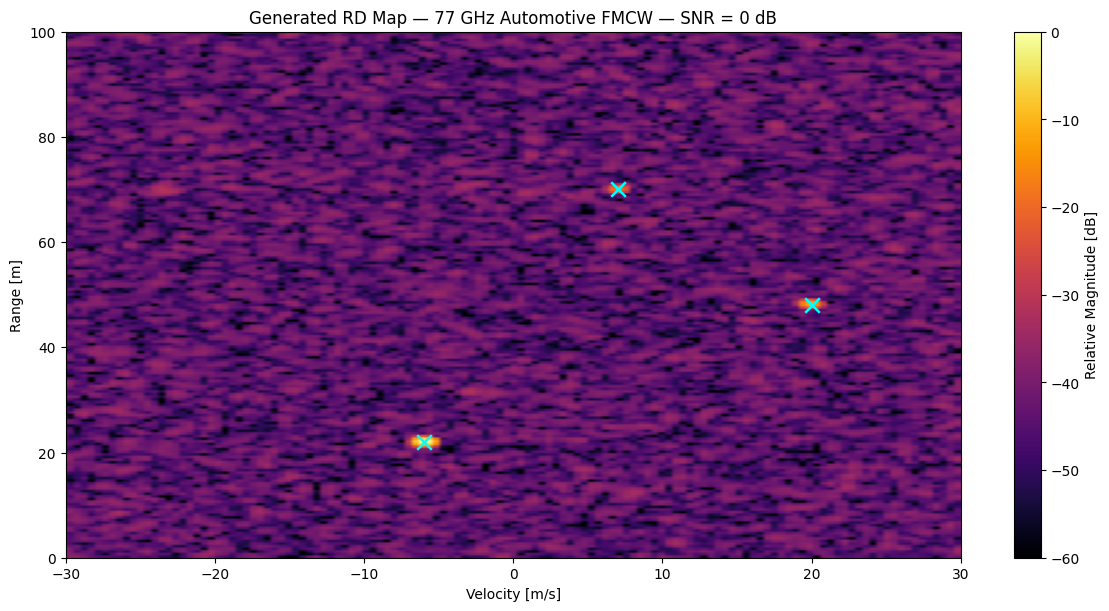

In [5]:

# ============================================================
# 7. Final RD map preview only
# ============================================================

extent = [velocity_axis[0], velocity_axis[-1], range_axis[0], range_axis[-1]]

fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)

im = ax.imshow(
    rd_db,
    aspect="auto",
    origin="lower",
    extent=extent,
    cmap=cmap,
    vmin=vmin_db,
    vmax=vmax_db,
)

for item in labels:
    ax.scatter(
        item["velocity_mps"],
        item["range_m"],
        marker="x",
        s=110,
        linewidths=1.8,
        color="cyan",
    )

ax.set_title(f"Generated RD Map — 77 GHz Automotive FMCW — SNR = {snr_db} dB")
ax.set_xlabel("Velocity [m/s]")
ax.set_ylabel("Range [m]")
ax.set_xlim(-v_plot_max, v_plot_max)
ax.set_ylim(0, r_plot_max)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Relative Magnitude [dB]")

plt.show()

## Random Data Generation

In [6]:
# ============================================================
# 8. Optional random dataset generation
# ============================================================

def generate_random_targets(rng, n_targets):
    target_list = []

    for _ in range(n_targets):
        r = rng.uniform(8.0, 95.0)
        v = rng.uniform(-22.0, 22.0)
        amp_db = rng.uniform(-10.0, 15.0)
        target_list.append((float(r), float(v), float(amp_db)))

    return target_list


if make_dataset:
    rng = np.random.default_rng(seed)
    dataset_dir.mkdir(parents=True, exist_ok=True)

    index = []

    for frame_idx in range(num_frames):
        frame_seed = int(rng.integers(0, 2**31 - 1))
        frame_snr = float(rng.choice(snr_choices))
        n_targets = int(rng.integers(num_targets_min, num_targets_max + 1))
        frame_targets = generate_random_targets(rng, n_targets)

        rd_db_i, rd_mag_i, _, range_axis_i, velocity_axis_i = simulate_frame(
            frame_targets,
            config,
            snr_db=frame_snr,
            seed=frame_seed,
        )

        labels_i = make_target_labels(frame_targets, range_axis_i, velocity_axis_i)
        mask_i = make_label_mask(labels_i, rd_db_i.shape, radius_r=1, radius_d=1)

        frame_dir = dataset_dir / f"frame_{frame_idx:06d}"
        save_frame(
            frame_dir,
            rd_db_i,
            rd_mag_i,
            labels_i,
            mask_i,
            range_axis_i,
            velocity_axis_i,
            config,
            frame_snr,
            frame_seed,
        )

        index.append({
            "frame_id": frame_idx,
            "path": str(frame_dir),
            "snr_db": frame_snr,
            "num_targets": n_targets,
        })

    with open(dataset_dir / "index.json", "w", encoding="utf-8") as f:
        json.dump(index, f, indent=2)

    with open(dataset_dir / "index.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["frame_id", "path", "snr_db", "num_targets"])
        writer.writeheader()
        writer.writerows(index)

    print(f"Generated {num_frames} frames in: {dataset_dir}")
    print(f"Dataset index saved to: {dataset_dir / 'index.csv'}")
else:
    print("Dataset loop is disabled. Set make_dataset = True when ready.")


Dataset loop is disabled. Set make_dataset = True when ready.
